# HEAL: Stroke Risk Assessment
## Phase 2: Exploratory Data Analysis & Baseline Model

Explore clinical features, set up the train/test split, and evaluate a baseline Logistic Regression model.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    ConfusionMatrixDisplay
)

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

print("Core libraries loaded successfully.")


Core libraries loaded successfully.


## 1. Load Dataset
Load the cleaned NHANES dataset `stroke_cleaned_dataset_corrected.csv`.

In [ ]:
# Load locked dataset
df = pd.read_csv("stroke_cleaned_dataset_corrected.csv")

print("Dataset loaded successfully.")
print(f"Total Rows (Participants): {df.shape[0]}")
print(f"Total Columns (Variables): {df.shape[1]}")
df.head()


Dataset loaded successfully.
Total Rows (Participants): 6053
Total Columns (Variables): 8


### Data Integrity Checks
Verify dataset shape, column types, missing values, and duplicates.

In [ ]:
print("=" * 60)
print("1. DATASET SHAPE & STRUCTURE")
print("=" * 60)
print(f"Shape: {df.shape}")
print("\nDataFrame Info:")
df.info()

print("\n" + "=" * 60)
print("2. DATA TYPES")
print("=" * 60)
print(df.dtypes)

print("\n" + "=" * 60)
print("3. MISSING VALUES AUDIT")
print("=" * 60)
missing_counts = df.isnull().sum()
print(missing_counts)
assert missing_counts.sum() == 0, "Warning: Unexpected missing values found!"
print("-> Audit Passed: 0 missing values detected across all columns.")

print("\n" + "=" * 60)
print("4. DUPLICATE ROWS AUDIT")
print("=" * 60)
dup_rows = df.duplicated().sum()
print(f"Full duplicate rows: {dup_rows}")
assert dup_rows == 0, "Warning: Duplicate rows detected!"
print("-> Audit Passed: 0 duplicate rows.")

print("\n" + "=" * 60)
print("5. DUPLICATE SEQN (PARTICIPANT ID) AUDIT")
print("=" * 60)
dup_seqn = df['SEQN'].duplicated().sum()
print(f"Duplicate SEQN identifiers: {dup_seqn}")
assert dup_seqn == 0, "Warning: Duplicate participant identifiers detected!"
print("-> Audit Passed: All 6,053 participants possess a unique SEQN.")


1. DATASET SHAPE & STRUCTURE
Shape: (6053, 8)

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6053 entries, 0 to 6052
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SEQN          6053 non-null   float64
 1   Systolic_BP   6053 non-null   float64
 2   Diastolic_BP  6053 non-null   float64
 3   BMI           6053 non-null   float64
 4   Diabetes      6053 non-null   float64
 5   HbA1c         6053 non-null   float64
 6   Smoker        6053 non-null   float64
 7   Stroke        6053 non-null   float64
dtypes: float64(8)
memory usage: 378.4 KB

2. DATA TYPES
SEQN            float64
Systolic_BP     float64
Diastolic_BP    float64
BMI             float64
Diabetes        float64
HbA1c           float64
Smoker          float64
Stroke          float64
dtype: object

3. MISSING VALUES AUDIT
SEQN            0
Systolic_BP     0
Diastolic_BP    0
BMI             0
Diabetes        0
HbA1c           0
Smoke

### Target Distribution
Check the count and proportion of stroke (1) and non-stroke (0) cases.

In [ ]:
print("=" * 60)
print("6. TARGET DISTRIBUTION (STROKE)")
print("=" * 60)
counts = df['Stroke'].value_counts()
pcts = df['Stroke'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': pcts.round(4)
})
summary_target.index = ['No Stroke (0.0)', 'Stroke (1.0)']
print(summary_target)

stroke_prev = pcts[1.0]
imbalance_ratio = counts[0.0] / counts[1.0]
print(f"\nStroke Prevalence: {stroke_prev:.2f}%")
print(f"Class Imbalance Ratio: {imbalance_ratio:.2f} : 1 (No Stroke to Stroke)")


6. TARGET DISTRIBUTION (STROKE)
                 Count  Percentage (%)
No Stroke (0.0)   5773         95.3742
Stroke (1.0)       280          4.6258

Stroke Prevalence: 4.63%
Class Imbalance Ratio: 20.62 : 1 (No Stroke to Stroke)


### Descriptive Statistics
Inspect summary statistics overall and grouped by stroke status.

In [ ]:
print("=" * 60)
print("7. DESCRIPTIVE STATISTICS (OVERALL)")
print("=" * 60)
print(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

print("\n" + "=" * 60)
print("FEATURE MEANS GROUPED BY STROKE STATUS")
print("=" * 60)
features_all = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker']
grouped_stats = df.groupby('Stroke')[features_all].agg(['mean', 'median', 'std']).T
print(grouped_stats.round(2))


7. DESCRIPTIVE STATISTICS (OVERALL)
               count           mean  ...       75%            max
SEQN          6053.0  136345.484884  ...  139304.0  142310.000000
Systolic_BP   6053.0     122.826147  ...     132.0     232.333333
Diastolic_BP  6053.0      74.712071  ...      81.0     139.000000
BMI           6053.0      29.808128  ...      33.5      74.800000
Diabetes      6053.0       0.142739  ...       0.0       1.000000
HbA1c         6053.0       5.773203  ...       5.9      17.100000
Smoker        6053.0       0.413679  ...       1.0       1.000000
Stroke        6053.0       0.046258  ...       0.0       1.000000

[8 rows x 8 columns]

FEATURE MEANS GROUPED BY STROKE STATUS
Stroke                  0.0     1.0
Systolic_BP  mean    122.50  129.54
             median  120.33  127.67
             std      17.58   20.43
Diastolic_BP mean     74.67   75.53
             median   74.00   74.00
             std      10.73   12.50
BMI          mean     29.80   29.89
             median 

## 2. Exploratory Data Analysis
Visualize distributions, comparisons, and correlations across clinical features. Note: observed correlations reflect cross-sectional associations and do not imply direct causation.

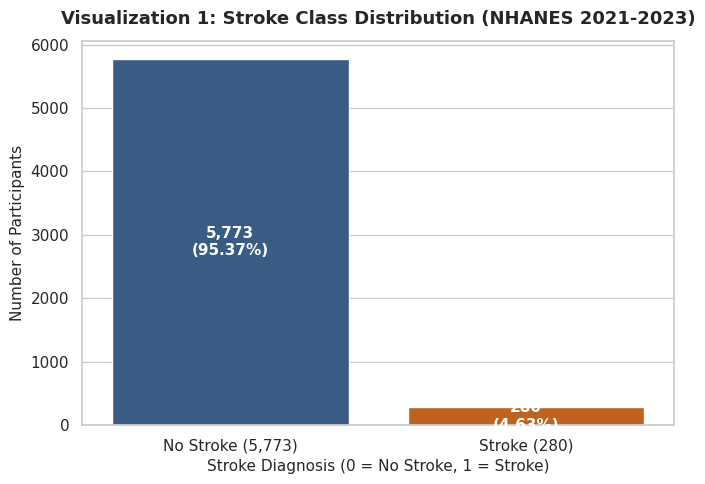

In [ ]:
# 1. Stroke Class Distribution
plt.figure(figsize=(7, 5))
palette = ['#2b5c8f', '#d95f02']
ax = sns.countplot(x='Stroke', hue='Stroke', data=df, palette=palette, legend=False)

total = len(df)
for p in ax.patches:
    h = p.get_height()
    pct = (h / total) * 100
    ax.annotate(f"{int(h):,}\n({pct:.2f}%)", 
                (p.get_x() + p.get_width() / 2., h / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.title("Visualization 1: Stroke Class Distribution (NHANES 2021-2023)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Stroke Diagnosis (0 = No Stroke, 1 = Stroke)", fontsize=11)
plt.ylabel("Number of Participants", fontsize=11)
plt.xticks([0, 1], ["No Stroke (5,773)", "Stroke (280)"])
plt.tight_layout()
plt.show()


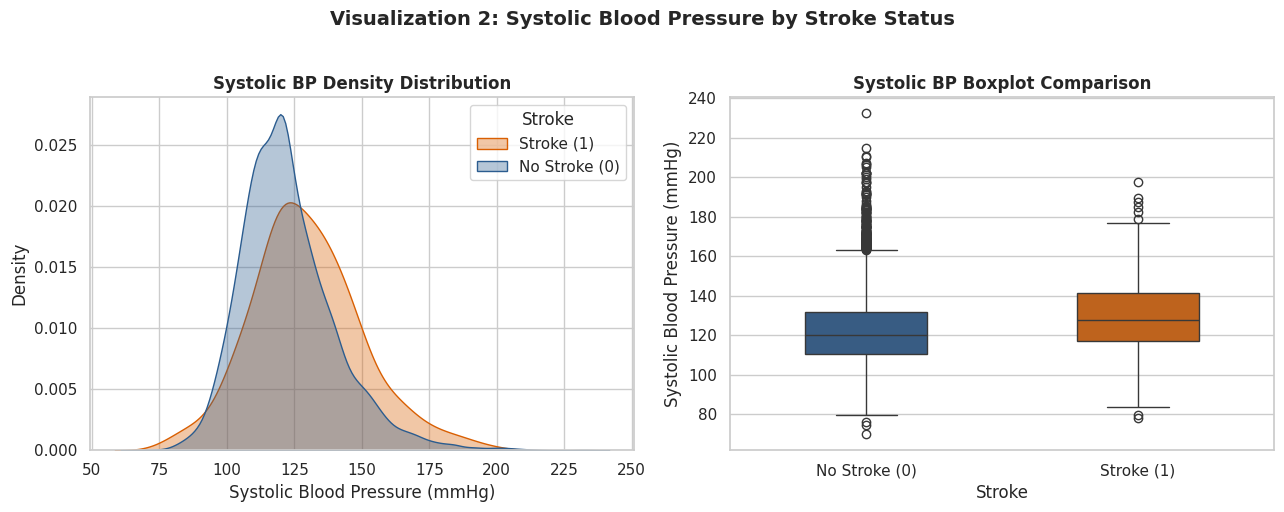

In [ ]:
# 2. Systolic Blood Pressure Distribution by Stroke
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# KDE distribution
sns.kdeplot(data=df, x='Systolic_BP', hue='Stroke', common_norm=False, 
            palette=['#2b5c8f', '#d95f02'], fill=True, alpha=0.35, ax=axes[0])
axes[0].set_title("Systolic BP Density Distribution", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Systolic Blood Pressure (mmHg)")
axes[0].legend(title='Stroke', labels=['Stroke (1)', 'No Stroke (0)'])

# Boxplot
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
sns.boxplot(x='Stroke', y='Systolic_BP', hue='Stroke', data=df, palette=['#2b5c8f', '#d95f02'], ax=axes[1], width=0.45, legend=False)
axes[1].set_title("Systolic BP Boxplot Comparison", fontsize=12, fontweight='bold')
# tick labels set above
axes[1].set_ylabel("Systolic Blood Pressure (mmHg)")

plt.suptitle("Visualization 2: Systolic Blood Pressure by Stroke Status", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


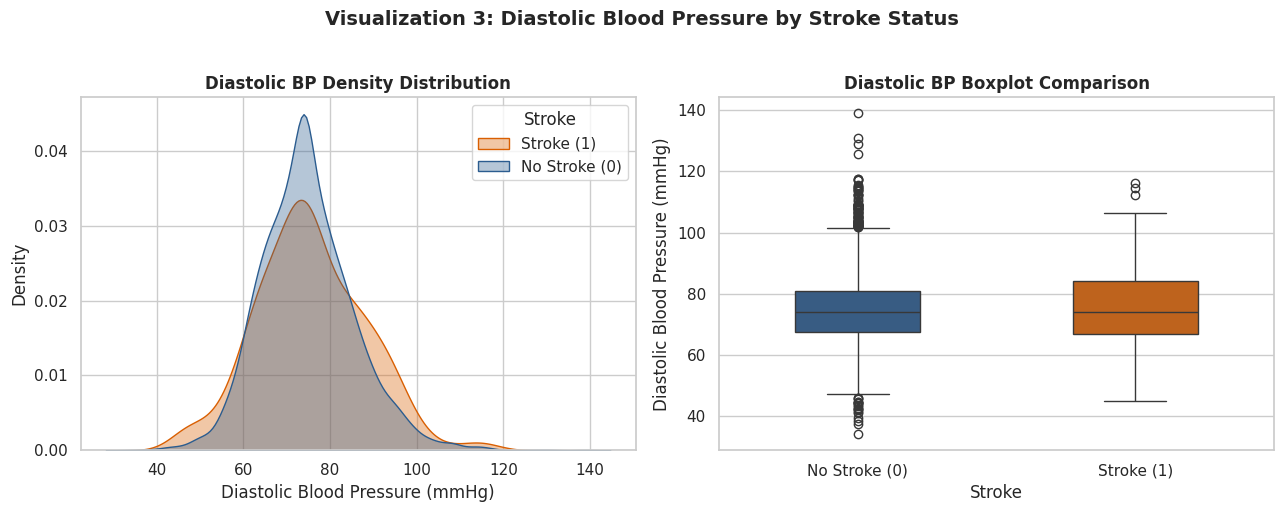

In [ ]:
# 3. Diastolic Blood Pressure Distribution by Stroke
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.kdeplot(data=df, x='Diastolic_BP', hue='Stroke', common_norm=False, 
            palette=['#2b5c8f', '#d95f02'], fill=True, alpha=0.35, ax=axes[0])
axes[0].set_title("Diastolic BP Density Distribution", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Diastolic Blood Pressure (mmHg)")
axes[0].legend(title='Stroke', labels=['Stroke (1)', 'No Stroke (0)'])

axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
sns.boxplot(x='Stroke', y='Diastolic_BP', hue='Stroke', data=df, palette=['#2b5c8f', '#d95f02'], ax=axes[1], width=0.45, legend=False)
axes[1].set_title("Diastolic BP Boxplot Comparison", fontsize=12, fontweight='bold')
# tick labels set above
axes[1].set_ylabel("Diastolic Blood Pressure (mmHg)")

plt.suptitle("Visualization 3: Diastolic Blood Pressure by Stroke Status", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


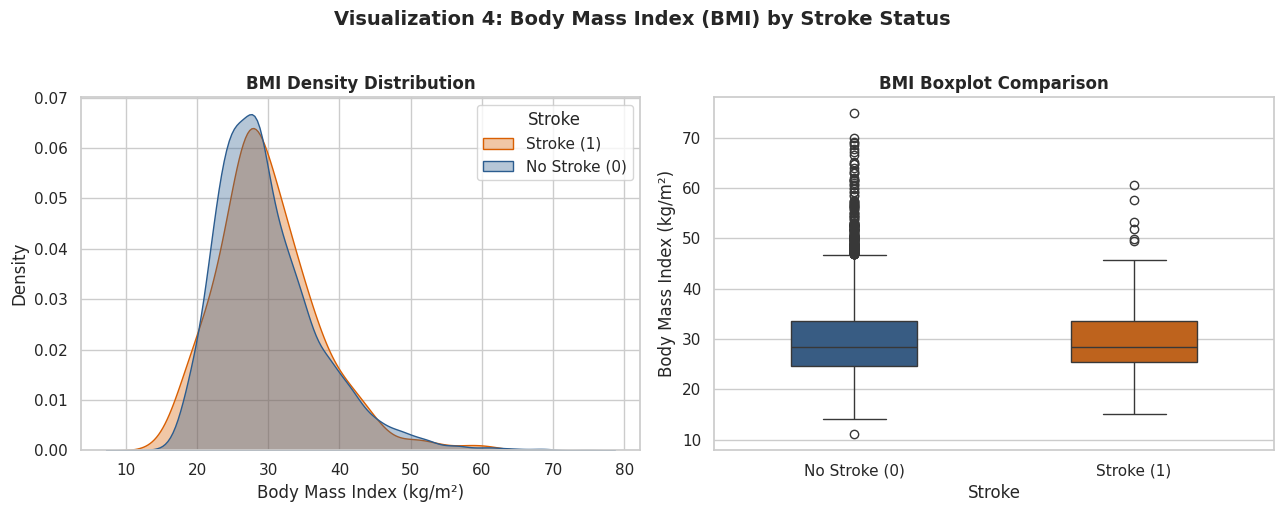

In [ ]:
# 4. BMI Distribution by Stroke
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.kdeplot(data=df, x='BMI', hue='Stroke', common_norm=False, 
            palette=['#2b5c8f', '#d95f02'], fill=True, alpha=0.35, ax=axes[0])
axes[0].set_title("BMI Density Distribution", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Body Mass Index (kg/m²)")
axes[0].legend(title='Stroke', labels=['Stroke (1)', 'No Stroke (0)'])

axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
sns.boxplot(x='Stroke', y='BMI', hue='Stroke', data=df, palette=['#2b5c8f', '#d95f02'], ax=axes[1], width=0.45, legend=False)
axes[1].set_title("BMI Boxplot Comparison", fontsize=12, fontweight='bold')
# tick labels set above
axes[1].set_ylabel("Body Mass Index (kg/m²)")

plt.suptitle("Visualization 4: Body Mass Index (BMI) by Stroke Status", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


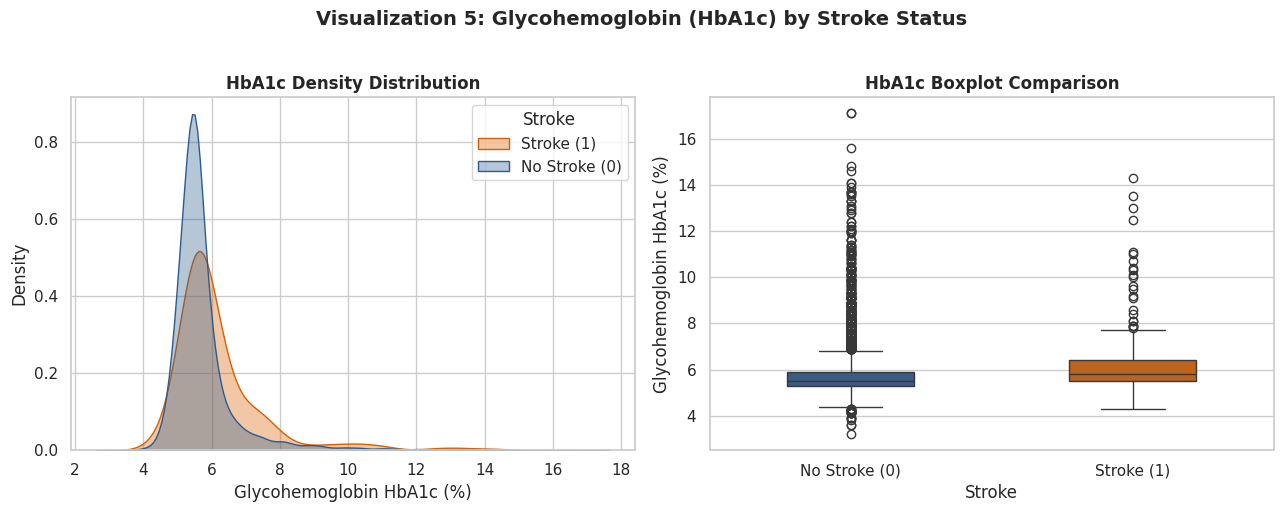

In [ ]:
# 5. HbA1c Distribution by Stroke
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.kdeplot(data=df, x='HbA1c', hue='Stroke', common_norm=False, 
            palette=['#2b5c8f', '#d95f02'], fill=True, alpha=0.35, ax=axes[0])
axes[0].set_title("HbA1c Density Distribution", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Glycohemoglobin HbA1c (%)")
axes[0].legend(title='Stroke', labels=['Stroke (1)', 'No Stroke (0)'])

axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
sns.boxplot(x='Stroke', y='HbA1c', hue='Stroke', data=df, palette=['#2b5c8f', '#d95f02'], ax=axes[1], width=0.45, legend=False)
axes[1].set_title("HbA1c Boxplot Comparison", fontsize=12, fontweight='bold')
# tick labels set above
axes[1].set_ylabel("Glycohemoglobin HbA1c (%)")

plt.suptitle("Visualization 5: Glycohemoglobin (HbA1c) by Stroke Status", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


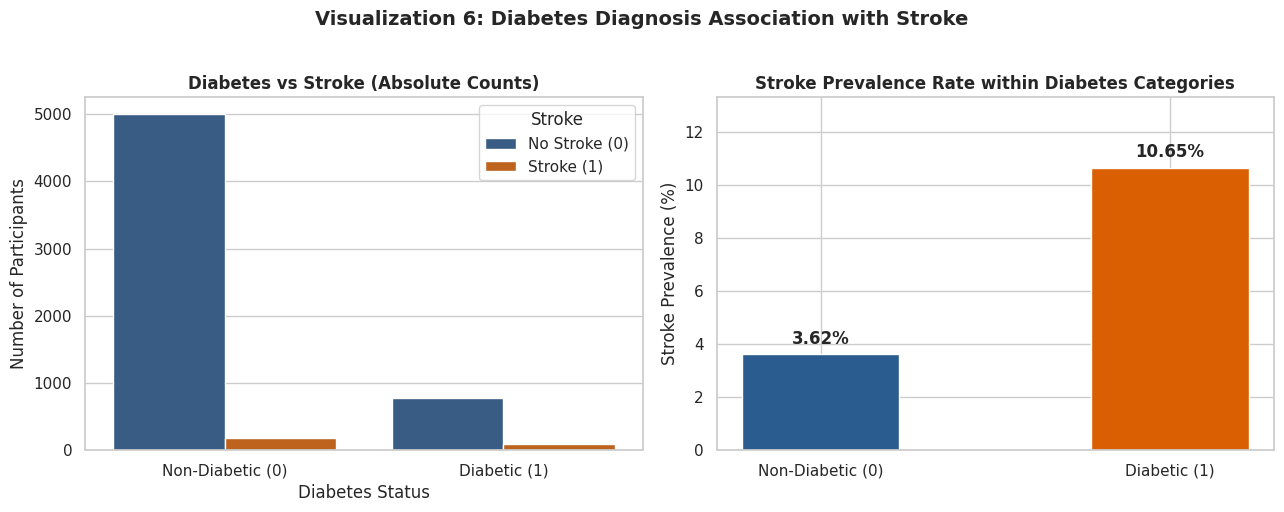

In [ ]:
# 6. Diabetes vs Stroke
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grouped Counts
sns.countplot(x='Diabetes', hue='Stroke', data=df, palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title("Diabetes vs Stroke (Absolute Counts)", fontsize=12, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])
axes[0].set_xlabel("Diabetes Status")
axes[0].set_ylabel("Number of Participants")
axes[0].legend(title='Stroke', labels=['No Stroke (0)', 'Stroke (1)'])

# Proportion of Stroke within Diabetes groups
diab_stroke_rate = df.groupby('Diabetes')['Stroke'].mean() * 100
bars = axes[1].bar(["Non-Diabetic (0)", "Diabetic (1)"], diab_stroke_rate, color=['#2b5c8f', '#d95f02'], width=0.45)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.25, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

axes[1].set_title("Stroke Prevalence Rate within Diabetes Categories", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Stroke Prevalence (%)")
axes[1].set_ylim(0, max(diab_stroke_rate) * 1.25)

plt.suptitle("Visualization 6: Diabetes Diagnosis Association with Stroke", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


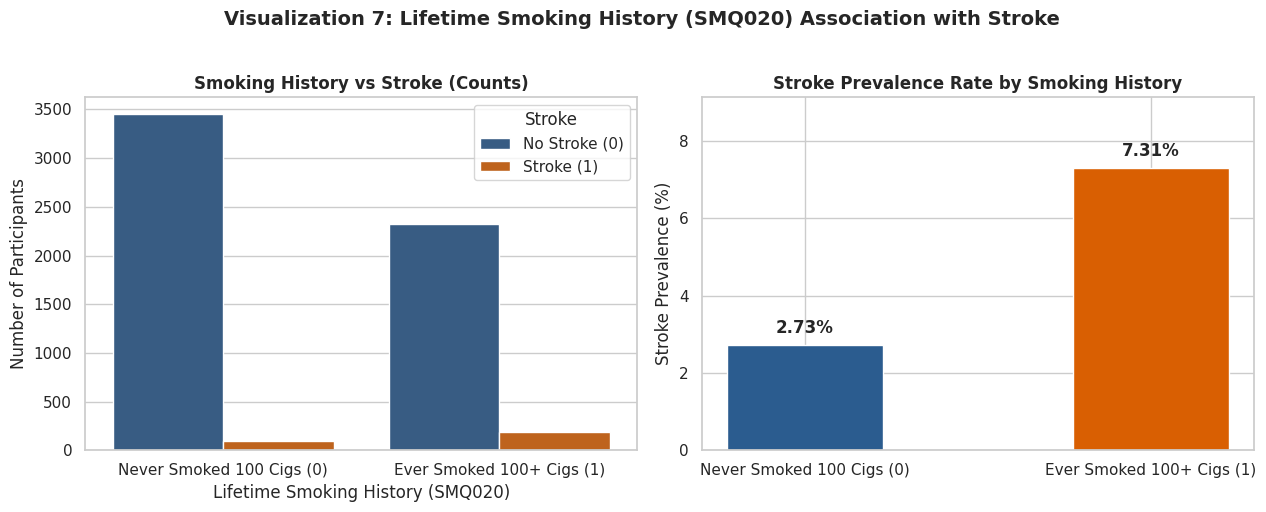

In [ ]:
# 7. Ever-Smoked (Smoker) vs Stroke
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Absolute counts
sns.countplot(x='Smoker', hue='Stroke', data=df, palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title("Smoking History vs Stroke (Counts)", fontsize=12, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Never Smoked 100 Cigs (0)', 'Ever Smoked 100+ Cigs (1)'])
axes[0].set_xlabel("Lifetime Smoking History (SMQ020)")
axes[0].set_ylabel("Number of Participants")
axes[0].legend(title='Stroke', labels=['No Stroke (0)', 'Stroke (1)'])

# Stroke Prevalence Rate within Smoking groups
smk_stroke_rate = df.groupby('Smoker')['Stroke'].mean() * 100
bars = axes[1].bar(["Never Smoked 100 Cigs (0)", "Ever Smoked 100+ Cigs (1)"], smk_stroke_rate, color=['#2b5c8f', '#d95f02'], width=0.45)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.2, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

axes[1].set_title("Stroke Prevalence Rate by Smoking History", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Stroke Prevalence (%)")
axes[1].set_ylim(0, max(smk_stroke_rate) * 1.25)

plt.suptitle("Visualization 7: Lifetime Smoking History (SMQ020) Association with Stroke", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


Correlations with Stroke Target:
Diabetes        0.1170
Smoker          0.1073
HbA1c           0.0848
Systolic_BP     0.0831
Diastolic_BP    0.0166
BMI             0.0026
Name: Stroke, dtype: float64


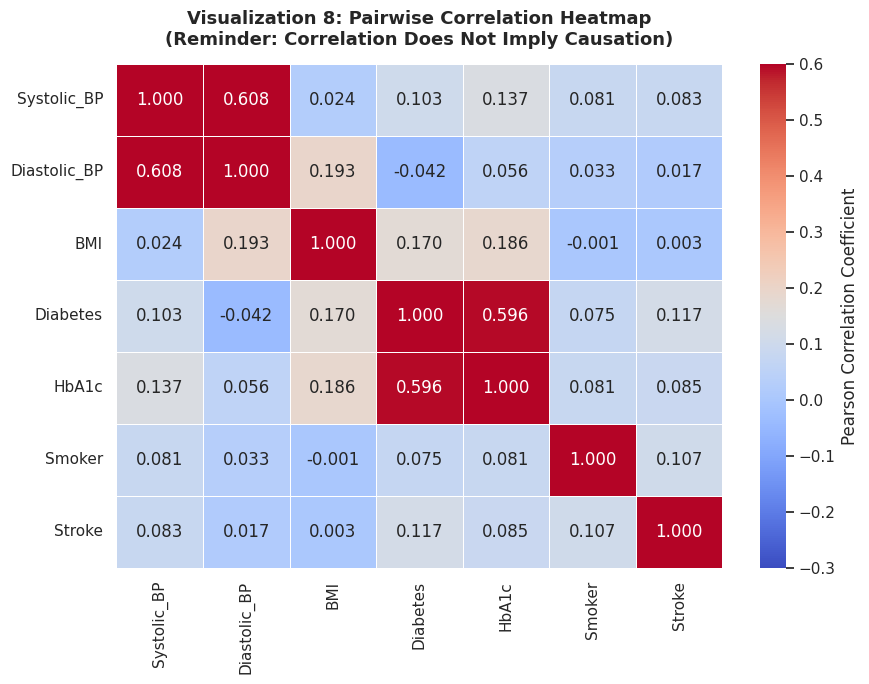

In [ ]:
# 8. Correlation Heatmap
plt.figure(figsize=(9, 7))

# Calculate Pearson correlation matrix for analytic variables
corr_cols = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker', 'Stroke']
corr_matrix = df[corr_cols].corr(method='pearson')

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.3, vmax=0.6,
            linewidths=0.5, cbar_kws={'label': 'Pearson Correlation Coefficient'})

plt.title("Visualization 8: Pairwise Correlation Heatmap\n(Reminder: Correlation Does Not Imply Causation)", 
          fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

print("Correlations with Stroke Target:")
print(corr_matrix['Stroke'].sort_values(ascending=False).drop('Stroke').round(4))


## 3. Preprocessing & Train/Test Split
- Split data into 80% train ($N = 4,842$) and 20% test ($N = 1,211$) using `stratify=y` and `random_state=42`.
- Fit `StandardScaler` strictly on numerical training features (`Systolic_BP`, `Diastolic_BP`, `BMI`, `HbA1c`) to prevent data leakage, and pass through binary features (`Diabetes`, `Smoker`).
- Drop `SEQN` from modeling inputs.

In [ ]:
# Feature Matrix X and Target y
features = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'Diabetes', 'HbA1c', 'Smoker']
target = 'Stroke'

X = df[features].copy()
y = df[target].copy()

# Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape} (80% of data)")
print(f"X_test shape : {X_test.shape} (20% of data)")
print(f"\ny_train distribution:\n{y_train.value_counts()}")
print(f"y_train stroke prevalence: {y_train.mean()*100:.2f}%")
print(f"\ny_test distribution:\n{y_test.value_counts()}")
print(f"y_test stroke prevalence : {y_test.mean()*100:.2f}%")

# Preprocessing Pipeline Definition
num_features = ['Systolic_BP', 'Diastolic_BP', 'BMI', 'HbA1c']
cat_features = ['Diabetes', 'Smoker']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', 'passthrough', cat_features)
    ]
)

print("\nPreprocessing Pipeline successfully defined.")


X_train shape: (4842, 6) (80% of data)
X_test shape : (1211, 6) (20% of data)

y_train distribution:
Stroke
0.0    4618
1.0     224
Name: count, dtype: int64
y_train stroke prevalence: 4.63%

y_test distribution:
Stroke
0.0    1155
1.0      56
Name: count, dtype: int64
y_test stroke prevalence : 4.62%

Preprocessing Pipeline successfully defined.


## 4. Train Baseline Model
Train a Logistic Regression model with `class_weight='balanced'`, `max_iter=1000`, and `random_state=42` to account for the 20.6:1 class imbalance.

In [ ]:
# Assemble end-to-end Pipeline
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Fit on training data ONLY
baseline_pipeline.fit(X_train, y_train)

print("Baseline Logistic Regression model training complete.")


Baseline Logistic Regression model training complete.


## 5. Model Evaluation
Evaluate the baseline model on the test set using Recall, Precision, F1-score, ROC-AUC, and PR-AUC. In this imbalanced setting, Recall and PR-AUC are far more informative than accuracy.

In [ ]:
# Generate predictions and predicted probabilities on held-out test set
y_pred = baseline_pipeline.predict(X_test)
y_proba = baseline_pipeline.predict_proba(X_test)[:, 1]

# Metric calculations
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Stroke)', 'Recall (Stroke)', 'F1-Score (Stroke)', 'ROC-AUC', 'PR-AUC'],
    'Value': [acc, prec, rec, f1, roc_auc, pr_auc],
    'Percentage': [f"{acc*100:.2f}%", f"{prec*100:.2f}%", f"{rec*100:.2f}%", f"{f1*100:.2f}%", f"{roc_auc:.4f}", f"{pr_auc:.4f}"]
})

print("=" * 60)
print("BASELINE LOGISTIC REGRESSION PERFORMANCE (TEST SET)")
print("=" * 60)
print(metrics_df.to_string(index=False))


BASELINE LOGISTIC REGRESSION PERFORMANCE (TEST SET)
            Metric    Value Percentage
          Accuracy 0.625103     62.51%
Precision (Stroke) 0.083682      8.37%
   Recall (Stroke) 0.714286     71.43%
 F1-Score (Stroke) 0.149813     14.98%
           ROC-AUC 0.716373     0.7164
            PR-AUC 0.100755     0.1008


Confusion Matrix Counts:
True Negatives  (TN) : 717 (Correctly classified non-stroke)
False Positives (FP) : 438 (Healthy flagged as high risk)
False Negatives (FN) : 16 (Missed stroke cases)
True Positives  (TP) : 40 (Correctly caught stroke cases)

DETAILED CLASSIFICATION REPORT
               precision    recall  f1-score   support

No Stroke (0)     0.9782    0.6208    0.7595      1155
   Stroke (1)     0.0837    0.7143    0.1498        56

     accuracy                         0.6251      1211
    macro avg     0.5309    0.6675    0.4547      1211
 weighted avg     0.9368    0.6251    0.7313      1211



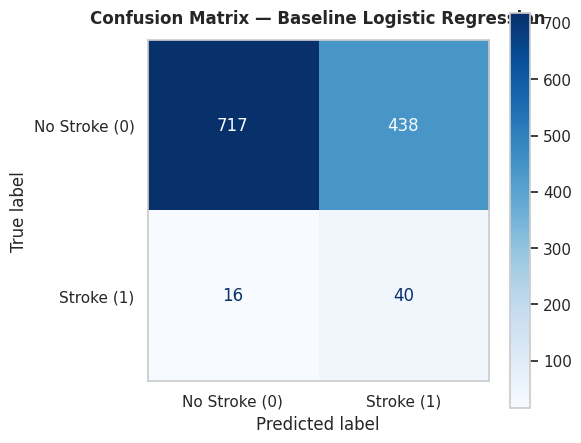

In [ ]:
# Confusion Matrix & Classification Report
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Stroke (0)', 'Stroke (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Confusion Matrix — Baseline Logistic Regression", fontsize=12, fontweight='bold', pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()

print("Confusion Matrix Counts:")
print(f"True Negatives  (TN) : {tn:,} (Correctly classified non-stroke)")
print(f"False Positives (FP) : {fp:,} (Healthy flagged as high risk)")
print(f"False Negatives (FN) : {fn:,} (Missed stroke cases)")
print(f"True Positives  (TP) : {tp:,} (Correctly caught stroke cases)")

print("\n" + "=" * 60)
print("DETAILED CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['No Stroke (0)', 'Stroke (1)'], digits=4))


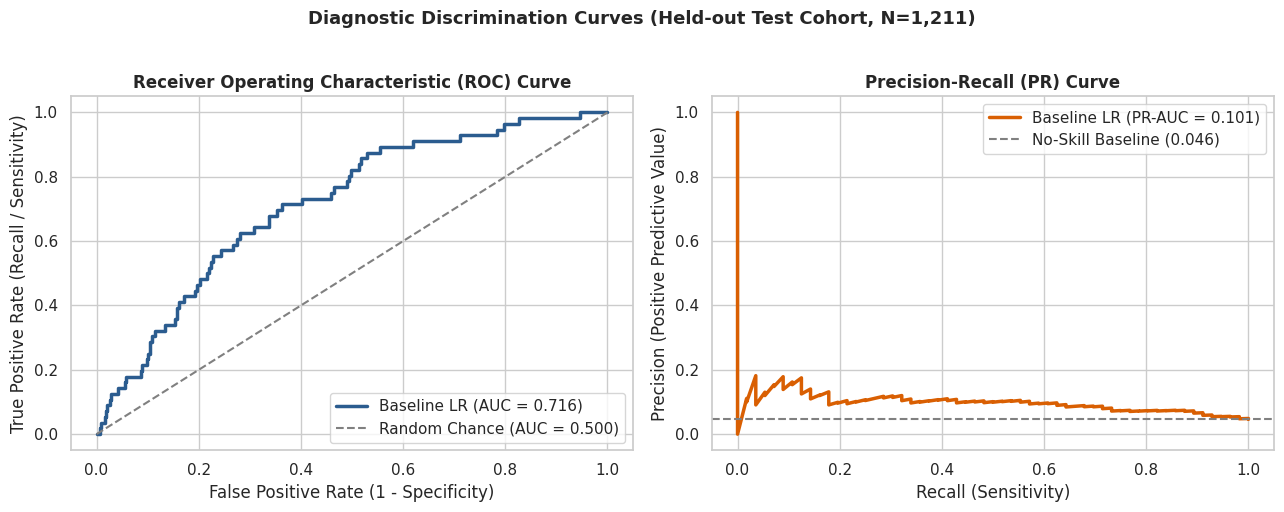

In [ ]:
# ROC and Precision-Recall Curves
fpr, tpr, _ = roc_curve(y_test, y_proba)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC Curve
axes[0].plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f'Baseline LR (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.500)')
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, fontweight='bold')
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall / Sensitivity)")
axes[0].legend(loc="lower right")

# Precision-Recall Curve
baseline_pr = y_test.mean()
axes[1].plot(recall_curve, precision_curve, color='#d95f02', lw=2.5, label=f'Baseline LR (PR-AUC = {pr_auc:.3f})')
axes[1].axhline(y=baseline_pr, color='gray', lw=1.5, linestyle='--', label=f'No-Skill Baseline ({baseline_pr:.3f})')
axes[1].set_title("Precision-Recall (PR) Curve", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (Positive Predictive Value)")
axes[1].legend(loc="upper right")

plt.suptitle("Diagnostic Discrimination Curves (Held-out Test Cohort, N=1,211)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
# Logistic Regression Coefficients and Odds Ratios (Interpretable Linear Baseline)
classifier = baseline_pipeline.named_steps['classifier']
coefs = classifier.coef_[0]
odds_ratios = np.exp(coefs)

coef_df = pd.DataFrame({
    'Feature': num_features + cat_features,
    'Coefficient (Log-Odds)': coefs,
    'Odds Ratio (OR)': odds_ratios,
    'Feature Type': ['Continuous (per 1 SD)'] * 4 + ['Binary (1 vs 0)'] * 2
}).sort_values(by='Odds Ratio (OR)', ascending=False)

print("=" * 70)
print("LOGISTIC REGRESSION FEATURE IMPORTANCE & ODDS RATIOS")
print("=" * 70)
print(coef_df.to_string(index=False))
print(f"\nModel Intercept: {classifier.intercept_[0]:.4f}")


LOGISTIC REGRESSION FEATURE IMPORTANCE & ODDS RATIOS
     Feature  Coefficient (Log-Odds)  Odds Ratio (OR)          Feature Type
      Smoker                1.055415         2.873168       Binary (1 vs 0)
    Diabetes                1.005473         2.733200       Binary (1 vs 0)
 Systolic_BP                0.426504         1.531893 Continuous (per 1 SD)
       HbA1c                0.125384         1.133584 Continuous (per 1 SD)
         BMI                0.000681         1.000681 Continuous (per 1 SD)
Diastolic_BP               -0.142270         0.867387 Continuous (per 1 SD)

Model Intercept: -0.8600


## 6. Summary of Findings

### Key Results:
- **Test Performance:** Baseline Logistic Regression achieved **71.43% Recall** (40/56 strokes caught), **62.08% Specificity** (717/1,155 cleared), **8.37% Precision**, **0.7164 ROC-AUC**, and **0.1008 PR-AUC** (more than double the 4.63% random prevalence).
- **Key Predictors:** Smoking ($	ext{OR} = 2.87$) and diabetes ($	ext{OR} = 2.73$) are the strongest risk factors in the model, followed by systolic BP ($	ext{OR} = 1.53$ per SD).

### Limitations:
- Low precision (8.37%) means 438 false positives, which is acceptable for an initial screening tool but needs refinement.
- Logistic regression assumes linear relationships and cannot automatically model non-linear interactions.
- Survey data is cross-sectional, so temporal causality cannot be established.

### Next Steps:
Phase 3 will compare this baseline against non-linear tree ensembles (Random Forest, Gradient Boosting, XGBoost).